# Cybersecurity Analytics & Intrusion Detection Dashboard
## Notebook 2 — Machine Learning (détection d'intrusion)

**Objectifs**
1. Charger les données nettoyées (Notebook 1)
2. Construire un **split temporel par blocs** (plus réaliste qu'un split aléatoire)
3. Entraîner 4 modèles : Logistic Regression (baseline), Random Forest, XGBoost, LightGBM
4. Évaluer avec des métriques adaptées au déséquilibre : **Macro F1**, **Recall par classe**, MCC
5. Mesurer la détection binaire (Attack / Benign) et le **taux de fausses alertes**
6. Sauvegarder le meilleur modèle et exporter les résultats pour Power BI

---

### Pourquoi ce protocole ?

**Problème 1 — Déséquilibre.** `Benign` ≈ 83 % des flux. Une Accuracy de 99 % ne dit rien sur `Bot` ou `Web Attack`. On regarde donc le **Macro F1** (moyenne des F1 par classe, chaque classe pèse pareil) et le **Recall par classe**.

**Problème 2 — Leakage temporel.** Dans CICIDS2017, des flux consécutifs d'un même outil d'attaque sont quasi identiques. Un split aléatoire place des « jumeaux » à la fois dans le train et le test → scores gonflés.

**Notre approche — split temporel par blocs.** Pour chaque couple *(fichier, label)* on trie les flux dans leur ordre d'origine : les **80 % premiers** vont au train, les **20 % derniers** au test, avec une **zone tampon de 1 %** entre les deux (jetée) pour éviter que des flux adjacents ne se retrouvent des deux côtés.

```text
Pour chaque (fichier, label) :
 |------------ 80 % train ------------|-1%-|---- ~19 % test ----|
   début de la capture            (tampon)            fin de la capture
```

> Limite assumée : l'ordre des lignes est *approximativement* chronologique (pas de timestamp dans cette version du dataset). Le Notebook 02b compare ce protocole à un split aléatoire.

## 1. Imports et configuration

In [1]:
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    matthews_corrcoef, precision_recall_fscore_support,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler

pd.set_option("display.max_columns", 100)

# ---- Configuration ----
SEED = 42
MIN_SAMPLES = 50      # classes avec moins d'exemples exclues du ML
TRAIN_FRAC = 0.80
GAP_FRAC = 0.01       # zone tampon entre train et test
FAST_MODE = False     # True = entraînement sur 20 % du train (pour tester rapidement le notebook)

PROCESSED_CSV = "../data/processed/cleaned_network_traffic.csv"
RESULTS_DIR = "../results/"
IMAGES_DIR = "../images/"
MODELS_DIR = "../models/"
for d in (RESULTS_DIR, IMAGES_DIR, MODELS_DIR):
    os.makedirs(d, exist_ok=True)

print("Configuration OK.")

C:\Users\HP\anaconda3\Lib\site-packages\dask\dataframe\__init__.py:49: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


Configuration OK.


## 2. Chargement des données

In [2]:
df = pd.read_csv(PROCESSED_CSV, low_memory=False)

# Colonnes qui ne sont PAS des features (cible, dérivées de la cible, traçabilité)
META_COLS = ["Label", "Attack_Category", "Is_Attack", "Source_File", "Day", "Row_Order"]
FEATURES = [c for c in df.columns if c not in META_COLS]
df[FEATURES] = df[FEATURES].astype("float32")

print("Shape :", df.shape)
print("Nombre de features :", len(FEATURES))
print()
print(df["Attack_Category"].value_counts())

Shape : (2520798, 85)
Nombre de features : 79

Attack_Category
Benign          2095057
DoS              193745
DDoS             128014
Port Scan         90694
Brute Force        9150
Web Attack         2143
Bot                1948
Infiltration         36
Heartbleed           11
Name: count, dtype: int64


## 3. Classes trop rares

`Infiltration` (36 flux) et `Heartbleed` (11 flux) sont trop rares pour être évaluées de façon fiable (quelques exemples seulement dans le test). On les exclut **uniquement du ML** ; elles restent visibles dans le dashboard Power BI.

In [3]:
class_counts = df["Attack_Category"].value_counts()
rare_classes = class_counts[class_counts < MIN_SAMPLES].index.tolist()
print("Classes exclues du ML :", rare_classes)

df_ml = df[~df["Attack_Category"].isin(rare_classes)].copy()
print("Shape pour le ML :", df_ml.shape)

le = LabelEncoder()
y = pd.Series(le.fit_transform(df_ml["Attack_Category"]), index=df_ml.index)
CLASSES = list(le.classes_)
BENIGN_CODE = int(le.transform(["Benign"])[0])

print("\nCorrespondance :", {c: int(i) for i, c in enumerate(CLASSES)})

Classes exclues du ML : ['Infiltration', 'Heartbleed']
Shape pour le ML : (2520751, 85)

Correspondance : {'Benign': 0, 'Bot': 1, 'Brute Force': 2, 'DDoS': 3, 'DoS': 4, 'Port Scan': 5, 'Web Attack': 6}


## 4. Split temporel par blocs

In [4]:
def blocked_temporal_split(data, train_frac=0.80, gap_frac=0.01):
    """
    Pour chaque couple (Source_File, Label), trie les flux par Row_Order :
      - fraction < train_frac                -> train
      - fraction >= train_frac + gap_frac    -> test
      - entre les deux                       -> zone tampon (ignorée)
    Retourne (index_train, index_test).
    """
    d = data[["Source_File", "Label", "Row_Order"]].sort_values(["Source_File", "Label", "Row_Order"])
    grp = d.groupby(["Source_File", "Label"], sort=False)
    frac = grp.cumcount() / grp["Row_Order"].transform("size")
    return d.index[frac < train_frac], d.index[frac >= train_frac + gap_frac]


train_idx, test_idx = blocked_temporal_split(df_ml, TRAIN_FRAC, GAP_FRAC)

assert len(set(train_idx) & set(test_idx)) == 0, "Chevauchement train/test !"

split_table = pd.DataFrame({
    "Train": df_ml.loc[train_idx, "Attack_Category"].value_counts(),
    "Test": df_ml.loc[test_idx, "Attack_Category"].value_counts(),
}).fillna(0).astype(int)
split_table["% Test"] = (split_table["Test"] / (split_table["Train"] + split_table["Test"]) * 100).round(1)

print(f"Train : {len(train_idx):,} | Test : {len(test_idx):,} | Tampon ignoré : {len(df_ml) - len(train_idx) - len(test_idx):,}")
split_table

Train : 2,016,609 | Test : 478,932 | Tampon ignoré : 25,210


,Train,Test,% Test
Attack_Category,,,
Benign,1676049,398057,19.2
DoS,154997,36810,19.2
DDoS,102412,24322,19.2
Port Scan,72556,17231,19.2
Brute Force,7321,1737,19.2
Web Attack,1715,405,19.1
Bot,1559,370,19.2


In [5]:
X_train, y_train = df_ml.loc[train_idx, FEATURES], y.loc[train_idx]
X_test, y_test = df_ml.loc[test_idx, FEATURES], y.loc[test_idx]

if FAST_MODE:
    X_train = X_train.sample(frac=0.2, random_state=SEED)
    y_train = y_train.loc[X_train.index]
    print("FAST_MODE actif : train réduit à", len(X_train))

# Scaling (uniquement utile à la Logistic Regression) : fit sur le TRAIN seulement
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

y_train_np, y_test_np = y_train.values, y_test.values
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (2016609, 79) | Test : (478932, 79)


## 5. Outils d'évaluation

- `evaluate()` calcule Accuracy, F1 pondéré, **Macro F1**, MCC, le temps d'entraînement et le **temps d'inférence** (ms pour 1 000 flux — important pour un IDS).
- Les résultats sont stockés dans des **dictionnaires** : relancer une cellule remplace l'entrée au lieu de l'ajouter en double.
- `sqrt_balanced_weights()` : poids de classes « adoucis » (racine du poids équilibré). Le poids `balanced` complet détruit la précision des classes rares (cf. LightGBM/LogReg du premier essai) ; la racine donne un compromis.

In [6]:
results = {}        # Model -> métriques globales
per_class = {}      # Model -> DataFrame métriques par classe
predictions = {}    # Model -> prédictions sur le test
models = {}         # Model -> objet modèle entraîné


def sqrt_balanced_weights(y_arr):
    counts = np.bincount(y_arr)
    w = (len(y_arr) / (len(counts) * counts)) ** 0.5
    return w[y_arr]


def run_model(name, model, X_tr, y_tr, X_te, y_te, **fit_kwargs):
    t0 = time.time()
    model.fit(X_tr, y_tr, **fit_kwargs)
    train_s = time.time() - t0

    t0 = time.time()
    y_pred = model.predict(X_te)
    infer_ms_1k = (time.time() - t0) / len(X_te) * 1000 * 1000

    labels = list(range(len(CLASSES)))
    p, r, f, s = precision_recall_fscore_support(y_te, y_pred, labels=labels, zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_te, y_pred, average="weighted", zero_division=0)

    results[name] = {
        "Accuracy": round(accuracy_score(y_te, y_pred), 4),
        "Precision_weighted": round(pw, 4),
        "Recall_weighted": round(rw, 4),
        "F1_weighted": round(fw, 4),
        "Macro_F1": round(float(np.mean(f)), 4),
        "MCC": round(matthews_corrcoef(y_te, y_pred), 4),
        "Train_seconds": round(train_s, 1),
        "Inference_ms_per_1000_flows": round(infer_ms_1k, 2),
    }
    per_class[name] = pd.DataFrame({
        "Model": name, "Class": CLASSES,
        "Precision": p.round(4), "Recall": r.round(4), "F1": f.round(4), "Support": s,
    })
    predictions[name] = y_pred
    models[name] = model

    print(f"[{name}] Macro F1 = {results[name]['Macro_F1']:.4f} | "
          f"Accuracy = {results[name]['Accuracy']:.4f} | "
          f"entraînement {train_s/60:.1f} min | inférence {infer_ms_1k:.1f} ms / 1000 flux")


w_train = sqrt_balanced_weights(y_train_np)
print("Outils prêts.")

Outils prêts.


## 6. Baseline — Logistic Regression

Modèle simple de référence. Si les modèles avancés ne la battent pas nettement, c'est qu'il y a un problème dans le pipeline.

In [7]:
run_model(
    "Logistic Regression (baseline)",
    LogisticRegression(max_iter=200, class_weight="balanced", random_state=SEED),
    X_train_s, y_train_np, X_test_s, y_test_np,
)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[Logistic Regression (baseline)] Macro F1 = 0.6269 | Accuracy = 0.8147 | entraînement 2.9 min | inférence 0.7 ms / 1000 flux


## 7. Random Forest

Hyperparamètres : ceux trouvés par `RandomizedSearchCV` (10 itérations, 3-fold, échantillon de 150k lignes) lors de la première version du projet — on ne relance pas la recherche pour gagner du temps.

In [8]:
RF_PARAMS = dict(n_estimators=300, min_samples_split=10, min_samples_leaf=1, max_depth=30)

run_model(
    "Random Forest",
    RandomForestClassifier(**RF_PARAMS, class_weight="balanced", random_state=SEED, n_jobs=-1),
    X_train, y_train_np, X_test, y_test_np,
)

[Random Forest] Macro F1 = 0.9000 | Accuracy = 0.9928 | entraînement 14.4 min | inférence 10.4 ms / 1000 flux


## 8. XGBoost

On compare **deux versions** : sans poids, et avec poids de classes « racine » (pour aider `Bot`, la classe la plus difficile).

In [9]:
XGB_PARAMS = dict(n_estimators=100, max_depth=6, learning_rate=0.2, subsample=0.7)

def make_xgb():
    return xgb.XGBClassifier(**XGB_PARAMS, tree_method="hist", eval_metric="mlogloss",
                             random_state=SEED, n_jobs=-1)

run_model("XGBoost", make_xgb(), X_train, y_train_np, X_test, y_test_np)

[XGBoost] Macro F1 = 0.8413 | Accuracy = 0.9955 | entraînement 3.2 min | inférence 5.0 ms / 1000 flux


In [10]:
run_model("XGBoost (poids sqrt)", make_xgb(), X_train, y_train_np, X_test, y_test_np,
          sample_weight=w_train)

[XGBoost (poids sqrt)] Macro F1 = 0.9264 | Accuracy = 0.9963 | entraînement 3.0 min | inférence 5.5 ms / 1000 flux


## 9. LightGBM

Le premier essai (avec `class_weight="balanced"`) avait une précision très faible sur les classes rares. Ici on utilise les **poids « racine »** à la place.

In [11]:
LGB_PARAMS = dict(n_estimators=200, num_leaves=31, max_depth=-1, learning_rate=0.05)

run_model(
    "LightGBM (poids sqrt)",
    lgb.LGBMClassifier(**LGB_PARAMS, random_state=SEED, n_jobs=-1, verbose=-1),
    X_train, y_train_np, X_test, y_test_np,
    sample_weight=w_train,
)

[LightGBM (poids sqrt)] Macro F1 = 0.9414 | Accuracy = 0.9963 | entraînement 3.0 min | inférence 22.6 ms / 1000 flux


## 10. Comparaison finale

Tri par **Macro F1** (métrique principale). L'Accuracy est donnée pour mémoire.

In [12]:
results_df = (
    pd.DataFrame(results).T.reset_index().rename(columns={"index": "Model"})
    .sort_values("Macro_F1", ascending=False).reset_index(drop=True)
)
per_class_df = pd.concat(per_class.values(), ignore_index=True)
results_df

,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,Macro_F1,MCC,Train_seconds,Inference_ms_per_1000_flows
0,LightGBM (poids sqrt),0.9963,0.9963,0.9963,0.9963,0.9414,0.9876,182.7,22.55
1,XGBoost (poids sqrt),0.9963,0.9964,0.9963,0.9963,0.9264,0.9876,182.6,5.51
2,Random Forest,0.9928,0.9928,0.9928,0.9926,0.9000,0.9758,864.2,10.45
3,XGBoost,0.9955,0.9950,0.9955,0.9952,0.8413,0.9850,192.2,5.03
4,Logistic Regression (baseline),0.8147,0.9657,0.8147,0.8796,0.6269,0.6255,173.6,0.74


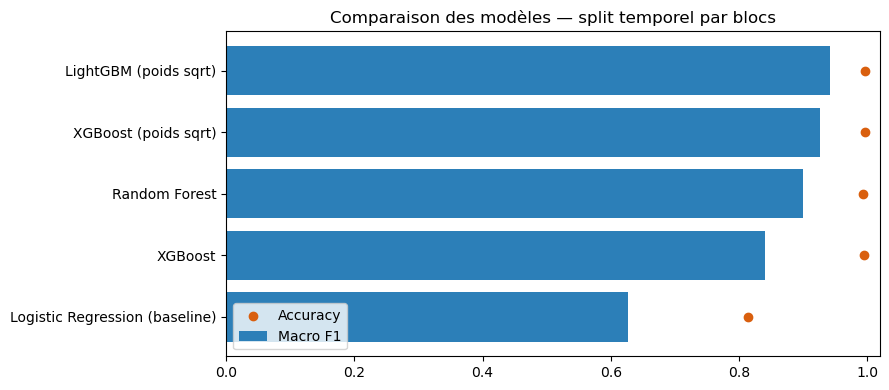

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_df = results_df.sort_values("Macro_F1")
ax.barh(plot_df["Model"], plot_df["Macro_F1"], color="#2c7fb8", label="Macro F1")
ax.scatter(plot_df["Accuracy"], plot_df["Model"], color="#d95f0e", zorder=3, label="Accuracy")
ax.set_xlim(0, 1.02)
ax.set_title("Comparaison des modèles — split temporel par blocs")
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(IMAGES_DIR + "model_comparison.png", dpi=150)
plt.show()

### Recall par classe (la vraie question : quelles attaques sont ratées ?)

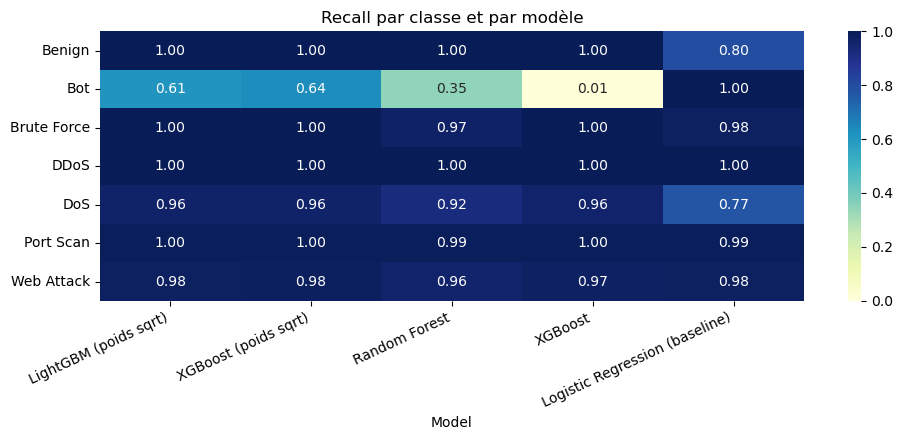

In [14]:
recall_pivot = per_class_df.pivot(index="Class", columns="Model", values="Recall")[results_df["Model"]]

plt.figure(figsize=(10, 4.5))
sns.heatmap(recall_pivot, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Recall par classe et par modèle")
plt.ylabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(IMAGES_DIR + "recall_by_class.png", dpi=150)
plt.show()

## 11. Meilleur modèle : rapport détaillé et matrice de confusion

In [15]:
best_name = results_df.iloc[0]["Model"]
best_pred = predictions[best_name]
print("Meilleur modèle (Macro F1) :", best_name, "\n")
print(classification_report(y_test_np, best_pred, target_names=CLASSES, zero_division=0))

Meilleur modèle (Macro F1) : LightGBM (poids sqrt) 

              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    398057
         Bot       0.72      0.61      0.66       370
 Brute Force       1.00      1.00      1.00      1737
        DDoS       1.00      1.00      1.00     24322
         DoS       1.00      0.96      0.98     36810
   Port Scan       0.95      1.00      0.97     17231
  Web Attack       0.98      0.98      0.98       405

    accuracy                           1.00    478932
   macro avg       0.95      0.93      0.94    478932
weighted avg       1.00      1.00      1.00    478932



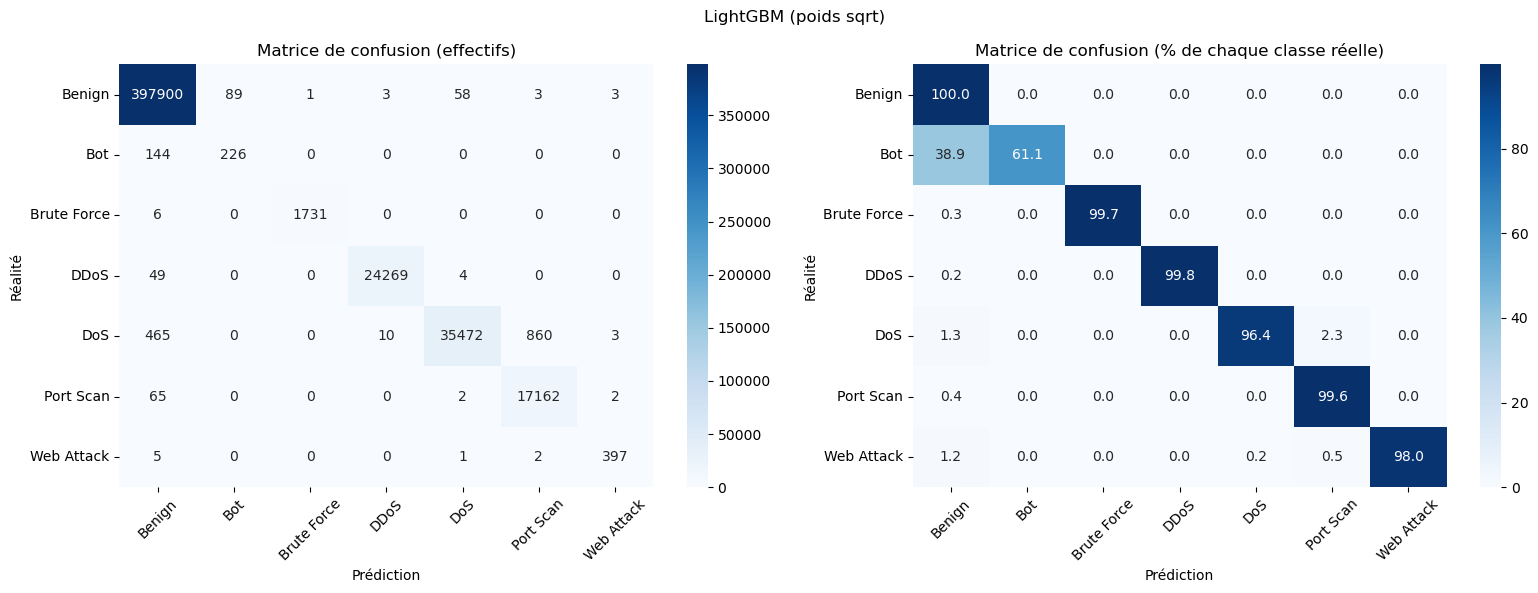

In [16]:
cm = confusion_matrix(y_test_np, best_pred, labels=range(len(CLASSES)))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100   # % de chaque classe réelle

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Matrice de confusion (effectifs)")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Matrice de confusion (% de chaque classe réelle)")
for ax in axes:
    ax.set_xlabel("Prédiction"); ax.set_ylabel("Réalité")
    ax.tick_params(axis="x", rotation=45)
plt.suptitle(best_name)
plt.tight_layout()
plt.savefig(IMAGES_DIR + "confusion_matrix.png", dpi=150)
plt.show()

# Format long pour Power BI
cm_long = pd.DataFrame(
    [(CLASSES[i], CLASSES[j], int(cm[i, j]), round(float(cm_pct[i, j]), 3))
     for i in range(len(CLASSES)) for j in range(len(CLASSES))],
    columns=["Actual", "Predicted", "Count", "Pct_of_Actual"],
)
cm_long.insert(0, "Model", best_name)

## 12. Détection binaire : Attack vs Benign

Pour un IDS réel, la question principale est : *« est-ce une attaque, oui ou non ? »* — et **combien de fausses alertes** on génère. On la déduit des prédictions multi-classes (toute prédiction ≠ Benign = alerte).

In [17]:
y_true_bin = (y_test_np != BENIGN_CODE).astype(int)
y_pred_bin = (best_pred != BENIGN_CODE).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true_bin, y_pred_bin).ravel()
binary_df = pd.DataFrame([{
    "Model": best_name,
    "Detection_rate_recall": round(tp / (tp + fn), 5),
    "Precision": round(tp / (tp + fp), 5),
    "False_alarm_rate": round(fp / (fp + tn), 5),
    "Missed_attacks": int(fn),
    "False_alarms": int(fp),
    "Attacks_in_test": int(tp + fn),
    "Benign_in_test": int(tn + fp),
}])
binary_df.T.rename(columns={0: "Valeur"})

,Valeur
Model,LightGBM (poids sqrt)
Detection_rate_recall,0.99092
Precision,0.99804
False_alarm_rate,0.00039
Missed_attacks,734
False_alarms,157
Attacks_in_test,80875
Benign_in_test,398057


## 13. Importance des features

Les features les plus utilisées par le meilleur modèle à base d'arbres — utile pour comprendre **quels indicateurs réseau** trahissent une attaque.

Importance calculée avec : LightGBM (poids sqrt)


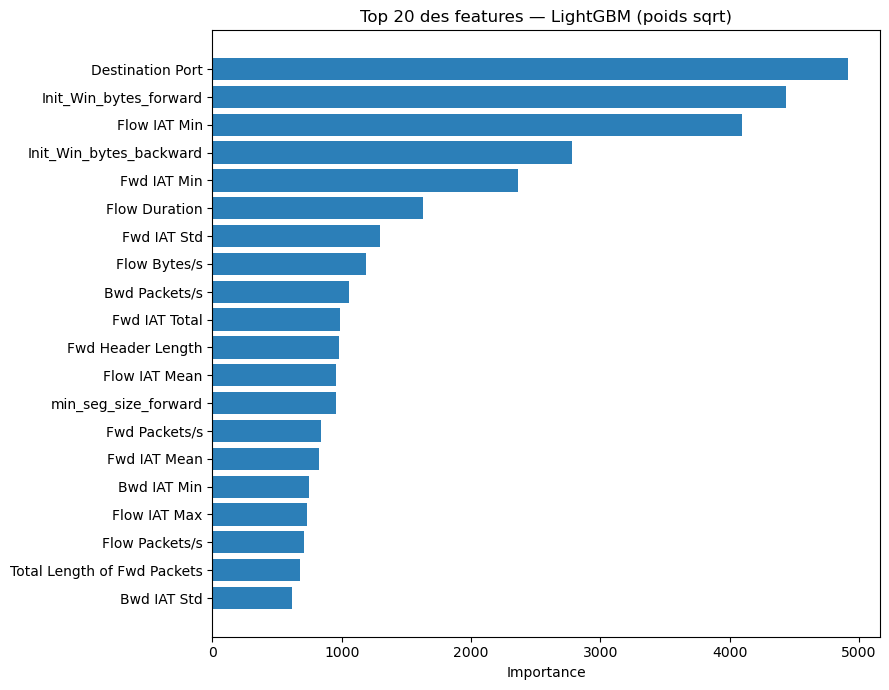

,Model,Feature,Importance
0,LightGBM (poids sqrt),Destination Port,4917
1,LightGBM (poids sqrt),Init_Win_bytes_forward,4434
2,LightGBM (poids sqrt),Flow IAT Min,4095
3,LightGBM (poids sqrt),Init_Win_bytes_backward,2780
4,LightGBM (poids sqrt),Fwd IAT Min,2366
5,LightGBM (poids sqrt),Flow Duration,1630
6,LightGBM (poids sqrt),Fwd IAT Std,1299
7,LightGBM (poids sqrt),Flow Bytes/s,1191
8,LightGBM (poids sqrt),Bwd Packets/s,1053
9,LightGBM (poids sqrt),Fwd IAT Total,989


In [18]:
tree_names = [n for n in results_df["Model"] if hasattr(models[n], "feature_importances_")]
imp_name = tree_names[0]
print("Importance calculée avec :", imp_name)

feature_importance_df = (
    pd.DataFrame({"Feature": FEATURES, "Importance": models[imp_name].feature_importances_})
    .sort_values("Importance", ascending=False).reset_index(drop=True)
)
feature_importance_df.insert(0, "Model", imp_name)

top20 = feature_importance_df.head(20)
plt.figure(figsize=(9, 7))
plt.barh(top20["Feature"][::-1], top20["Importance"][::-1], color="#2c7fb8")
plt.title(f"Top 20 des features — {imp_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(IMAGES_DIR + "feature_importance.png", dpi=150)
plt.show()
top20

## 14. Sauvegarde du modèle

On sauvegarde la meilleure variante **XGBoost** (format JSON, léger et portable) + un fichier `meta.json` (liste des features, classes, protocole). Le Random Forest n'est pas sauvegardé : avec 300 arbres de profondeur 30 sur 2 M de lignes il pèse plusieurs Go.

In [19]:
xgb_names = [n for n in results_df["Model"] if n.startswith("XGBoost")]
saved_name = xgb_names[0]
models[saved_name].save_model(MODELS_DIR + "xgb_model.json")

meta = {
    "model_name": saved_name,
    "features": FEATURES,
    "classes": CLASSES,
    "benign_class": "Benign",
    "split_protocol": f"blocked temporal split per (file, label): {TRAIN_FRAC:.0%} train / {GAP_FRAC:.0%} gap / rest test",
    "metrics": results[saved_name],
}
with open(MODELS_DIR + "meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

print("Modèle sauvegardé :", saved_name, "->", MODELS_DIR)
print("Taille :", round(os.path.getsize(MODELS_DIR + "xgb_model.json") / 1e6, 1), "Mo")

Modèle sauvegardé : XGBoost (poids sqrt) -> ../models/
Taille : 1.9 Mo


## 15. Export pour Power BI

In [20]:
results_df.to_csv(RESULTS_DIR + "model_results.csv", index=False)
per_class_df.to_csv(RESULTS_DIR + "per_class_metrics.csv", index=False)
cm_long.to_csv(RESULTS_DIR + "confusion_matrix.csv", index=False)
binary_df.to_csv(RESULTS_DIR + "binary_detection.csv", index=False)
feature_importance_df.to_csv(RESULTS_DIR + "feature_importance.csv", index=False)
split_table.reset_index().rename(columns={"index": "Attack_Category"}).to_csv(RESULTS_DIR + "split_summary.csv", index=False)

print("Exports :", sorted(os.listdir(RESULTS_DIR)))

Exports : ['.gitkeep', 'attack_summary.csv', 'binary_detection.csv', 'confusion_matrix.csv', 'daily_summary.csv', 'data_quality.csv', 'feature_importance.csv', 'label_summary.csv', 'model_results.csv', 'per_class_metrics.csv', 'port_summary.csv', 'split_summary.csv', 'traffic_stats.csv']
